In [21]:
import json
import tiktoken
from tqdm.notebook import tqdm
import pandas as pd

In [28]:
MAX_TOKEN_LENGTH = 8191

In [34]:
def load_chunks(corpus_path="../data/corpus.jsonl"):
    with open(corpus_path, "r", encoding="utf-8") as corpus:
        for line in corpus:
            r = json.loads(line)
            yield {"id": f"{r['pmid']}:0", "pmid": r["pmid"],
                "text": f"{r['title']}\n\n{r['abstract']}",
                "meta": {k: r[k] for k in ("journal", "pub_year", "pub_types", "mesh_terms", "doi")}}

In [35]:
def get_token_length(text, model="text-embedding-3-small"):
    """Returns the number of tokens in a text string."""
    encoding = tiktoken.encoding_for_model(model)
    return len(encoding.encode(text))

In [36]:
chunks = list(load_chunks())

In [37]:
chunk_lengths = []
for chunk in tqdm(chunks):
    chunk_lengths.append(get_token_length(chunk["text"]))

  0%|          | 0/5000 [00:00<?, ?it/s]

In [38]:
chunk_lengths_df = pd.DataFrame(chunk_lengths, columns=["token_length"])

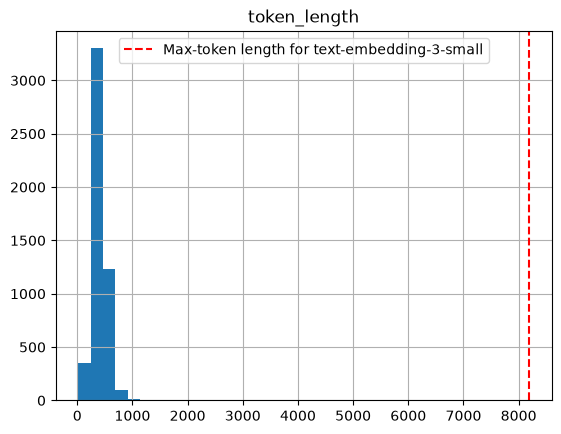

In [33]:
from matplotlib import pyplot as plt
ax = chunk_lengths_df.hist()[0, 0]
assert max(chunk_lengths_df["token_length"]) <= MAX_TOKEN_LENGTH, "Some chunks exceed the max token length for text-embedding-3-small"
ax.axvline(MAX_TOKEN_LENGTH, color="red", linestyle="--", label="Max-token length for text-embedding-3-small")
ax.legend()
plt.show()

## Note: The histogram shows that most chunks are well below the max token length for text-embedding-3-small and there are no chunks that exceed the max token length. This means that we can safely use text-embedding-3-small for embedding the chunks without worrying about truncation or loss of information.